In [1]:

!pip -q install pandas numpy scikit-learn xgboost joblib matplotlib seaborn


In [2]:

from google.colab import files
import os
import zipfile

uploaded = files.upload()

os.makedirs("/content/datasets", exist_ok=True)

for filename in uploaded:
    if filename.lower().endswith(".zip"):
        with zipfile.ZipFile(filename) as z:
            z.extractall("/content/datasets")
        print("Extracted:", filename)

print("Dataset upload completed.")


Saving Scenario A1-ARFF.zip to Scenario A1-ARFF.zip
Saving Scenario A2-ARFF.zip to Scenario A2-ARFF.zip
Saving Scenario B-ARFF.zip to Scenario B-ARFF.zip
Extracted: Scenario A1-ARFF.zip
Extracted: Scenario A2-ARFF.zip
Extracted: Scenario B-ARFF.zip
Dataset upload completed.


In [3]:

import pandas as pd
import numpy as np
import re
from pathlib import Path

def load_arff(path):
    attributes = []
    rows = []
    in_data = False

    with open(path, "r", encoding="utf-8-sig", errors="replace") as f:
        for raw in f:
            line = raw.strip()

            if not line or line.startswith("%"):
                continue

            if line.lower().startswith("@attribute"):
                match = re.match(
                    r"@attribute\s+(['\"]?)([^\s'\"]+)\1",
                    line,
                    flags=re.I
                )
                if match:
                    attributes.append(match.group(2))
                continue

            if line.lower().startswith("@data"):
                in_data = True
                continue

            if not in_data or line.startswith("@"):
                continue

            values = [v.strip() for v in line.rstrip(",").split(",")]

            if len(values) == len(attributes):
                rows.append(values)

    if not rows:
        raise ValueError(f"No valid rows in {path}")

    df = pd.DataFrame(rows, columns=attributes)

    label_col = next(
        (c for c in df.columns if c.lower() in ("class1", "class")),
        None
    )

    if label_col is None:
        raise ValueError(f"No class label in {path}")

    df = df.rename(columns={label_col: "label"})
    df["label"] = df["label"].str.strip()

    df = df[df["label"].isin(["VPN", "Non-VPN"])].copy()

    for col in df.columns.drop("label"):
        df[col] = pd.to_numeric(df[col], errors="coerce")

    return df

datasets = {}

for path in Path("/content/datasets").rglob("*.arff"):
    df = load_arff(path)
    datasets[str(path.relative_to("/content/datasets"))] = df
    print(path.name, ":", df.shape)

print("Total ARFF files:", len(datasets))


TimeBasedFeatures-Dataset-15s-VPN.arff : (18758, 24)
TimeBasedFeatures-Dataset-120s-VPN.arff : (10782, 24)
TimeBasedFeatures-Dataset-30s-VPN.arff : (14651, 24)
TimeBasedFeatures-Dataset-60s-VPN.arff : (15515, 24)
TimeBasedFeatures-Dataset-30s-AllinOne.arff : (0, 24)
TimeBasedFeatures-Dataset-60s.arff : (0, 24)
TimeBasedFeatures-Dataset-120s.arff : (0, 24)
TimeBasedFeatures-Dataset-30s.arff : (0, 24)
TimeBasedFeatures-Dataset-15s.arff : (0, 24)
TimeBasedFeatures-Dataset-120s-AllinOne.arff : (0, 24)
TimeBasedFeatures-Dataset-15s-AllinOne.arff : (0, 24)
TimeBasedFeatures-Dataset-60s-AllinOne.arff : (0, 24)
TimeBasedFeatures-Dataset-30s-NO-VPN.arff : (0, 24)
TimeBasedFeatures-Dataset-15s-VPN.arff : (0, 24)
TimeBasedFeatures-Dataset-60s-NO-VPN.arff : (0, 24)
TimeBasedFeatures-Dataset-120s-NO-VPN.arff : (0, 24)
TimeBasedFeatures-Dataset-120s-VPN.arff : (0, 24)
TimeBasedFeatures-Dataset-30s-VPN.arff : (0, 24)
TimeBasedFeatures-Dataset-60s-VPN.arff : (0, 24)
TimeBasedFeatures-Dataset-15s-NO-VP

In [4]:

for name, df in datasets.items():
    print("\nDataset:", name)
    print("Rows:", len(df))
    print("Features:", len(df.columns) - 1)
    print("Labels:")
    print(df["label"].value_counts())
    print("-" * 50)



Dataset: Scenario A1-ARFF/TimeBasedFeatures-Dataset-15s-VPN.arff
Rows: 18758
Features: 23
Labels:
label
VPN        9793
Non-VPN    8965
Name: count, dtype: int64
--------------------------------------------------

Dataset: Scenario A1-ARFF/TimeBasedFeatures-Dataset-120s-VPN.arff
Rows: 10782
Features: 23
Labels:
label
VPN        5631
Non-VPN    5151
Name: count, dtype: int64
--------------------------------------------------

Dataset: Scenario A1-ARFF/TimeBasedFeatures-Dataset-30s-VPN.arff
Rows: 14651
Features: 23
Labels:
label
VPN        7734
Non-VPN    6917
Name: count, dtype: int64
--------------------------------------------------

Dataset: Scenario A1-ARFF/TimeBasedFeatures-Dataset-60s-VPN.arff
Rows: 15515
Features: 23
Labels:
label
Non-VPN    8580
VPN        6935
Name: count, dtype: int64
--------------------------------------------------

Dataset: Scenario B-ARFF/TimeBasedFeatures-Dataset-30s-AllinOne.arff
Rows: 0
Features: 23
Labels:
Series([], Name: count, dtype: int64)
------

In [5]:

candidates = [
    name for name in datasets
    if "15s" in name.lower() and "a1" in name.lower()
]

assert len(candidates) == 1, (
    f"Expected one A1 15s dataset, found: {candidates}"
)

df = datasets[candidates[0]].copy()

X = df.drop(columns=["label"])
y = df["label"].map({"Non-VPN": 0, "VPN": 1})

X = X.replace([np.inf, -np.inf], np.nan)

print("Selected:", candidates[0])
print("Features:", X.columns.tolist())
print("Shape:", X.shape)
print("Labels:", y.value_counts().to_dict())


Selected: Scenario A1-ARFF/TimeBasedFeatures-Dataset-15s-VPN.arff
Features: ['duration', 'total_fiat', 'total_biat', 'min_fiat', 'min_biat', 'max_fiat', 'max_biat', 'mean_fiat', 'mean_biat', 'flowPktsPerSecond', 'flowBytesPerSecond', 'min_flowiat', 'max_flowiat', 'mean_flowiat', 'std_flowiat', 'min_active', 'mean_active', 'max_active', 'std_active', 'min_idle', 'mean_idle', 'max_idle', 'std_idle']
Shape: (18758, 23)
Labels: {1: 9793, 0: 8965}


In [6]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)


Training: (15006, 23)
Testing: (3752, 23)


In [7]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

rf = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=20,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf.fit(X_train, y_train)

print("Random Forest trained successfully.")


Random Forest trained successfully.


In [8]:

from xgboost import XGBClassifier

xgb = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    ))
])

xgb.fit(X_train, y_train)

print("XGBoost trained successfully.")


XGBoost trained successfully.



 Random Forest
              precision    recall  f1-score   support

     Non-VPN       0.93      0.90      0.92      1793
         VPN       0.91      0.94      0.92      1959

    accuracy                           0.92      3752
   macro avg       0.92      0.92      0.92      3752
weighted avg       0.92      0.92      0.92      3752



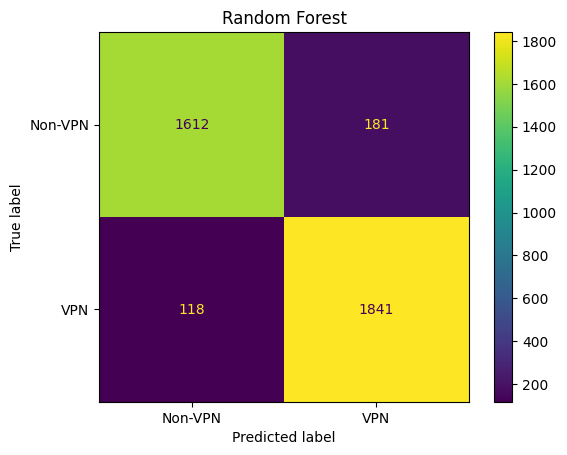


 XGBoost
              precision    recall  f1-score   support

     Non-VPN       0.93      0.90      0.92      1793
         VPN       0.91      0.94      0.92      1959

    accuracy                           0.92      3752
   macro avg       0.92      0.92      0.92      3752
weighted avg       0.92      0.92      0.92      3752



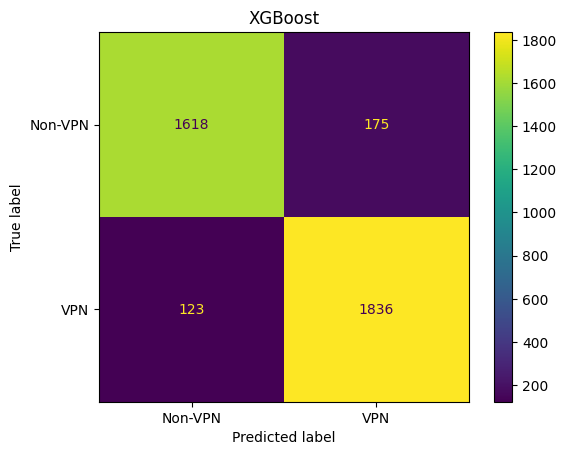

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Random Forest,0.920309,0.910485,0.939765,0.924893,0.976686
1,XGBoost,0.920576,0.912979,0.937213,0.924937,0.976975


In [9]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

models = {
    "Random Forest": rf,
    "XGBoost": xgb
}

results = []

for name, model in models.items():
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob)
    })

    print("\n", name)
    print(classification_report(
        y_test, pred,
        target_names=["Non-VPN", "VPN"]
    ))

    ConfusionMatrixDisplay.from_predictions(
        y_test, pred,
        display_labels=["Non-VPN", "VPN"]
    )
    plt.title(name)
    plt.show()

results_df = pd.DataFrame(results)
display(results_df)


In [10]:

import joblib
import json
import sklearn
import xgboost

best_name = results_df.sort_values(
    "F1", ascending=False
).iloc[0]["Model"]

best_model = models[best_name]

joblib.dump(best_model, "vpn_classifier.joblib")

metadata = {
    "model_name": best_name,
    "task": "VPN vs Non-VPN classification",
    "feature_columns": X.columns.tolist(),
    "labels": {"0": "Non-VPN", "1": "VPN"},
    "training_dataset": candidates[0],
    "observation_window": "15s",
    "sklearn_version": sklearn.__version__,
    "xgboost_version": xgboost.__version__,
    "evaluation": "Preliminary random split; not session-independent"
}

with open("model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

print("Best model:", best_name)
print("Saved model and metadata.")


Best model: XGBoost
Saved model and metadata.


In [11]:

import pandas as pd

summary = []

for name, df in datasets.items():
    features = set(df.columns) - {"label"}

    summary.append({
        "Dataset": name,
        "Rows": len(df),
        "Features": len(features),
        "Labels": ", ".join(sorted(df["label"].unique()))
    })

display(pd.DataFrame(summary))


,Dataset,Rows,Features,Labels
0,Scenario A1-ARFF/TimeBasedFeatures-Dataset-15s...,18758,23,"Non-VPN, VPN"
1,Scenario A1-ARFF/TimeBasedFeatures-Dataset-120...,10782,23,"Non-VPN, VPN"
2,Scenario A1-ARFF/TimeBasedFeatures-Dataset-30s...,14651,23,"Non-VPN, VPN"
3,Scenario A1-ARFF/TimeBasedFeatures-Dataset-60s...,15515,23,"Non-VPN, VPN"
4,Scenario B-ARFF/TimeBasedFeatures-Dataset-30s-...,0,23,
5,Scenario B-ARFF/TimeBasedFeatures-Dataset-60s....,0,23,
6,Scenario B-ARFF/TimeBasedFeatures-Dataset-120s...,0,23,
7,Scenario B-ARFF/TimeBasedFeatures-Dataset-30s....,0,23,
8,Scenario B-ARFF/TimeBasedFeatures-Dataset-15s....,0,23,
9,Scenario B-ARFF/TimeBasedFeatures-Dataset-120s...,0,23,


In [12]:


from pathlib import Path

for path in sorted(Path("/content/datasets").rglob("*.arff")):
    if "Scenario A1" in str(path):
        continue

    print("\nFILE:", path.name)
    print("SCENARIO:", path.parent.name)

    with open(path, "r", encoding="utf-8-sig",
              errors="replace") as f:
        lines = f.readlines()

    attributes = [
        line.strip()
        for line in lines
        if line.strip().lower().startswith("@attribute")
    ]

    data_start = next(
        (i for i, line in enumerate(lines)
         if line.strip().lower().startswith("@data")),
        None
    )

    print("Last attributes:", attributes[-3:])
    print("Data section:", data_start)

    if data_start is not None:
        examples = [
            line.strip()
            for line in lines[data_start + 1:]
            if line.strip() and not line.strip().startswith("%")
        ][:3]

        for example in examples:
            print("ROW:", example[:250])

    print("-" * 60)



FILE: TimeBasedFeatures-Dataset-120s-NO-VPN.arff
SCENARIO: Scenario A2-ARFF
Last attributes: ['@ATTRIBUTE max_idle NUMERIC,,,,,,,,,,,,,,,,,,,,,,,', '@ATTRIBUTE std_idle NUMERIC,,,,,,,,,,,,,,,,,,,,,,,', '@ATTRIBUTE class1 {BROWSING,CHAT,STREAMING,MAIL,VOIP,P2P,FT},,,,,,,,,,,,,,,,,']
Data section: 26
ROW: 119994459,119994459,119970125,0,0,1399330,1211310,2348.136256898,513.2675260334,2373.7929432225,2724140.23717545,0,1208289,421.2682127924,9107.7591776459,1753114,11300000,39438693,16000000,1014624,1139537.6,1208289,74997.3853814251,BROWSING
ROW: 143704195,143704195,42106019,0,0,101572528,854818,6986.1057365095,636.8988368048,603.2043810551,645213.405217572,0,101572528,1657.8320181814,345078.17588796,143704195,144000000,143704195,0,101572528,102000000,101572528,0,BROWSING
ROW: 119994980,119994980,119966891,7,0,819852,819602,10201.9197415406,2341.4113043309,525.0302971008,597136.113527416,0,819581,1904.6822222222,17736.0172652298,-1,0,-1,0,-1,0,-1,0,BROWSING
-----------------------------

In [13]:

from collections import Counter
from pathlib import Path

for path in sorted(Path("/content/datasets").rglob("*.arff")):
    if "Scenario A1" in str(path):
        continue

    with open(path, encoding="utf-8-sig",
              errors="replace") as f:
        lines = f.readlines()

    data_start = next(
        (i for i, line in enumerate(lines)
         if line.strip().lower() == "@data"),
        None
    )

    if data_start is None:
        print(path.name, "NO DATA SECTION")
        continue

    rows = [
        line.strip().rstrip(",")
        for line in lines[data_start + 1:]
        if line.strip()
        and not line.strip().startswith("%")
    ]

    labels = Counter(
        row.split(",")[-1].strip().strip("'\"")
        for row in rows
        if not row.startswith("{")
    )

    print("\n", path.parent.name, "/", path.name)
    print("Raw rows:", len(rows))
    print("Last-column values:", labels.most_common(12))


TimeBasedFeatures-Dataset-120s-NO-VPN.arff NO DATA SECTION
TimeBasedFeatures-Dataset-120s-VPN.arff NO DATA SECTION
TimeBasedFeatures-Dataset-15s-NO-VPN.arff NO DATA SECTION
TimeBasedFeatures-Dataset-15s-VPN.arff NO DATA SECTION
TimeBasedFeatures-Dataset-30s-NO-VPN.arff NO DATA SECTION
TimeBasedFeatures-Dataset-30s-VPN.arff NO DATA SECTION
TimeBasedFeatures-Dataset-60s-NO-VPN.arff NO DATA SECTION
TimeBasedFeatures-Dataset-60s-VPN.arff NO DATA SECTION
TimeBasedFeatures-Dataset-120s-AllinOne.arff NO DATA SECTION
TimeBasedFeatures-Dataset-120s.arff NO DATA SECTION
TimeBasedFeatures-Dataset-15s-AllinOne.arff NO DATA SECTION
TimeBasedFeatures-Dataset-15s.arff NO DATA SECTION
TimeBasedFeatures-Dataset-30s-AllinOne.arff NO DATA SECTION
TimeBasedFeatures-Dataset-30s.arff NO DATA SECTION
TimeBasedFeatures-Dataset-60s-AllinOne.arff NO DATA SECTION
TimeBasedFeatures-Dataset-60s.arff NO DATA SECTION


In [14]:

from pathlib import Path
import pandas as pd
import numpy as np
import re
import csv

ROOT = Path("/content/datasets")

def load_arff_fixed(path):
    attributes = []
    rows = []
    in_data = False

    with open(path, encoding="utf-8-sig", errors="replace") as f:
        for raw in f:
            line = raw.strip()

            if not line or line.startswith("%"):
                continue

            if line.lower().startswith("@attribute"):
                match = re.match(
                    r"@attribute\s+(['\"]?)([^\s'\"]+)\1",
                    line,
                    re.IGNORECASE
                )
                if match:
                    attributes.append(match.group(2))
                continue

            if line.lower().startswith("@data"):
                in_data = True
                continue

            if not in_data or line.startswith("@"):
                continue

            values = next(csv.reader([line]))
            values = [v.strip().strip("'\"") for v in values]

            # Ignore extra empty fields caused by trailing commas
            while len(values) > len(attributes) and values[-1] == "":
                values.pop()

            if len(values) != len(attributes):
                continue

            if all(v == "" for v in values):
                continue

            rows.append(values)

    if not attributes:
        raise ValueError(f"No attributes found: {path}")

    df = pd.DataFrame(rows, columns=attributes)

    label_col = next(
        (c for c in df.columns if c.lower() in ("class1", "class")),
        None
    )

    if label_col is None:
        raise ValueError(f"Missing class column: {path}")

    df = df.rename(columns={label_col: "label"})
    df["label"] = df["label"].str.strip().str.upper()

    df = df[df["label"].ne("")].copy()

    for col in df.columns.drop("label"):
        df[col] = pd.to_numeric(df[col], errors="coerce")

    return df

datasets = {}

for path in sorted(ROOT.rglob("*.arff")):
    key = str(path.relative_to(ROOT))
    datasets[key] = load_arff_fixed(path)

summary = []

for name, df in datasets.items():
    summary.append({
        "Dataset": name,
        "Rows": len(df),
        "Features": len(df.columns) - 1,
        "Labels": ", ".join(sorted(df["label"].unique()))
    })

display(pd.DataFrame(summary))


,Dataset,Rows,Features,Labels
0,Scenario A1-ARFF/TimeBasedFeatures-Dataset-120...,10782,23,"NON-VPN, VPN"
1,Scenario A1-ARFF/TimeBasedFeatures-Dataset-15s...,18758,23,"NON-VPN, VPN"
2,Scenario A1-ARFF/TimeBasedFeatures-Dataset-30s...,14651,23,"NON-VPN, VPN"
3,Scenario A1-ARFF/TimeBasedFeatures-Dataset-60s...,15515,23,"NON-VPN, VPN"
4,Scenario A2-ARFF/TimeBasedFeatures-Dataset-120...,5151,23,"BROWSING, CHAT, FT, MAIL, P2P, STREAMING, VOIP"
5,Scenario A2-ARFF/TimeBasedFeatures-Dataset-120...,5631,23,"VPN-BROWSING, VPN-CHAT, VPN-FT, VPN-MAIL, VPN-..."
6,Scenario A2-ARFF/TimeBasedFeatures-Dataset-15s...,8965,23,"BROWSING, CHAT, FT, MAIL, P2P, STREAMING, VOIP"
7,Scenario A2-ARFF/TimeBasedFeatures-Dataset-15s...,9793,23,"VPN-BROWSING, VPN-CHAT, VPN-FT, VPN-MAIL, VPN-..."
8,Scenario A2-ARFF/TimeBasedFeatures-Dataset-30s...,6917,23,"BROWSING, CHAT, FT, MAIL, P2P, STREAMING, VOIP"
9,Scenario A2-ARFF/TimeBasedFeatures-Dataset-30s...,7734,23,"VPN-BROWSING, VPN-CHAT, VPN-FT, VPN-MAIL, VPN-..."


In [15]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)
import matplotlib.pyplot as plt

def find_dataset(scenario, filename):
    matches = [
        key for key in datasets
        if scenario.lower() in key.lower()
        and Path(key).name.lower() == filename.lower()
    ]
    if len(matches) != 1:
        raise ValueError(f"Expected one match: {scenario}/{filename}. Found {matches}")
    return datasets[matches[0]].copy()

train_df = find_dataset(
    "Scenario A1",
    "TimeBasedFeatures-Dataset-15s-VPN.arff"
) if any(
    "Scenario A1" in k and
    Path(k).name == "TimeBasedFeatures-Dataset-15s-VPN.arff"
    for k in datasets
) else None

# A1 contains a combined binary-label file.
if train_df is None:
    matches = [
        k for k in datasets
        if "Scenario A1" in k
        and "15s" in Path(k).name.lower()
    ]
    assert len(matches) == 1, f"Ambiguous A1 files: {matches}"
    train_df = datasets[matches[0]].copy()

test_nonvpn = find_dataset(
    "Scenario A2",
    "TimeBasedFeatures-Dataset-15s-NO-VPN.arff"
)
test_vpn = find_dataset(
    "Scenario A2",
    "TimeBasedFeatures-Dataset-15s-VPN.arff"
)

test_df = pd.concat(
    [test_nonvpn, test_vpn],
    ignore_index=True
)

def binary_label(value):
    value = str(value).strip().upper()
    if value == "VPN" or value.startswith("VPN-"):
        return 1
    if value == "NON-VPN" or value in {
        "BROWSING", "CHAT", "STREAMING",
        "MAIL", "VOIP", "P2P", "FT"
    }:
        return 0
    raise ValueError(f"Unknown label: {value}")

y_train = train_df["label"].map(binary_label)
y_test = test_df["label"].map(binary_label)

features = list(train_df.drop(columns="label").columns)
test_features = list(test_df.drop(columns="label").columns)

assert set(features) == set(test_features), (
    "Feature schemas differ. Do not train until they match."
)

X_train = train_df[features].replace([np.inf, -np.inf], np.nan)
X_test = test_df[features].replace([np.inf, -np.inf], np.nan)

assert len(X_train) > 0 and len(X_test) > 0
assert y_train.nunique() == 2 and y_test.nunique() == 2

models = {
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            max_depth=20,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]),
    "XGBoost": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", XGBClassifier(
            n_estimators=300,
            max_depth=6,
            learning_rate=0.05,
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        ))
    ])
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred)
    })

    print(f"\n{name}")
    print(classification_report(
        y_test, pred,
        target_names=["Non-VPN", "VPN"]
    ))

display(pd.DataFrame(results).sort_values("F1", ascending=False))



Random Forest
              precision    recall  f1-score   support

     Non-VPN       0.75      0.74      0.75      8965
         VPN       0.77      0.78      0.77      9793

    accuracy                           0.76     18758
   macro avg       0.76      0.76      0.76     18758
weighted avg       0.76      0.76      0.76     18758


XGBoost
              precision    recall  f1-score   support

     Non-VPN       0.73      0.76      0.75      8965
         VPN       0.77      0.74      0.76      9793

    accuracy                           0.75     18758
   macro avg       0.75      0.75      0.75     18758
weighted avg       0.75      0.75      0.75     18758



,Model,Accuracy,Precision,Recall,F1
0,Random Forest,0.758503,0.765192,0.775350,0.770237
1,XGBoost,0.751359,0.772095,0.743082,0.757311


In [16]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)
import matplotlib.pyplot as plt

def find_dataset(scenario, filename):
    matches = [
        key for key in datasets
        if scenario.lower() in key.lower()
        and Path(key).name.lower() == filename.lower()
    ]
    if len(matches) != 1:
        raise ValueError(f"Expected one match: {scenario}/{filename}. Found {matches}")
    return datasets[matches[0]].copy()

train_df = find_dataset(
    "Scenario A1",
    "TimeBasedFeatures-Dataset-15s-VPN.arff"
) if any(
    "Scenario A1" in k and
    Path(k).name == "TimeBasedFeatures-Dataset-15s-VPN.arff"
    for k in datasets
) else None

# A1 contains a combined binary-label file.
if train_df is None:
    matches = [
        k for k in datasets
        if "Scenario A1" in k
        and "15s" in Path(k).name.lower()
    ]
    assert len(matches) == 1, f"Ambiguous A1 files: {matches}"
    train_df = datasets[matches[0]].copy()

test_nonvpn = find_dataset(
    "Scenario A2",
    "TimeBasedFeatures-Dataset-15s-NO-VPN.arff"
)
test_vpn = find_dataset(
    "Scenario A2",
    "TimeBasedFeatures-Dataset-15s-VPN.arff"
)

test_df = pd.concat(
    [test_nonvpn, test_vpn],
    ignore_index=True
)

def binary_label(value):
    value = str(value).strip().upper()
    if value == "VPN" or value.startswith("VPN-"):
        return 1
    if value == "NON-VPN" or value in {
        "BROWSING", "CHAT", "STREAMING",
        "MAIL", "VOIP", "P2P", "FT"
    }:
        return 0
    raise ValueError(f"Unknown label: {value}")

y_train = train_df["label"].map(binary_label)
y_test = test_df["label"].map(binary_label)

features = list(train_df.drop(columns="label").columns)
test_features = list(test_df.drop(columns="label").columns)

assert set(features) == set(test_features), (
    "Feature schemas differ. Do not train until they match."
)

X_train = train_df[features].replace([np.inf, -np.inf], np.nan)
X_test = test_df[features].replace([np.inf, -np.inf], np.nan)

assert len(X_train) > 0 and len(X_test) > 0
assert y_train.nunique() == 2 and y_test.nunique() == 2

models = {
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            max_depth=20,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]),
    "XGBoost": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", XGBClassifier(
            n_estimators=300,
            max_depth=6,
            learning_rate=0.05,
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        ))
    ])
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred)
    })

    print(f"\n{name}")
    print(classification_report(
        y_test, pred,
        target_names=["Non-VPN", "VPN"]
    ))

display(pd.DataFrame(results).sort_values("F1", ascending=False))



Random Forest
              precision    recall  f1-score   support

     Non-VPN       0.75      0.74      0.75      8965
         VPN       0.77      0.78      0.77      9793

    accuracy                           0.76     18758
   macro avg       0.76      0.76      0.76     18758
weighted avg       0.76      0.76      0.76     18758


XGBoost
              precision    recall  f1-score   support

     Non-VPN       0.73      0.76      0.75      8965
         VPN       0.77      0.74      0.76      9793

    accuracy                           0.75     18758
   macro avg       0.75      0.75      0.75     18758
weighted avg       0.75      0.75      0.75     18758



,Model,Accuracy,Precision,Recall,F1
0,Random Forest,0.758503,0.765192,0.775350,0.770237
1,XGBoost,0.751359,0.772095,0.743082,0.757311


In [17]:

train_hashes = set(
    pd.util.hash_pandas_object(
        X_train.reset_index(drop=True),
        index=False
    )
)

test_hashes = set(
    pd.util.hash_pandas_object(
        X_test.reset_index(drop=True),
        index=False
    )
)

overlap = len(train_hashes & test_hashes)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Identical feature records shared:", overlap)
print("Overlap proportion:",
      overlap / max(1, len(test_hashes)))


Training rows: 18758
Testing rows: 18758
Identical feature records shared: 0
Overlap proportion: 0.0


In [18]:

print("TRAINING SOURCE")
print("Rows:", len(train_df))
print("Labels:", train_df["label"].value_counts().to_dict())

print("\nTEST SOURCE")
print("Rows:", len(test_df))
print("Labels:", test_df["label"].value_counts().to_dict())

print("\nA2 SOURCE FILE COUNTS")
print("Non-VPN file:", len(test_nonvpn))
print("VPN file:", len(test_vpn))

print("\nTRAINING LABELS")
print(sorted(train_df["label"].unique()))

print("\nTESTING LABELS")
print(sorted(test_df["label"].unique()))

print("\nFEATURE SCHEMA MATCH")
print(list(train_df.drop(columns="label").columns) ==
      list(test_df.drop(columns="label").columns))


TRAINING SOURCE
Rows: 18758
Labels: {'VPN': 9793, 'NON-VPN': 8965}

TEST SOURCE
Rows: 18758
Labels: {'VOIP': 2826, 'BROWSING': 2500, 'VPN-BROWSING': 2500, 'VPN-VOIP': 2271, 'VPN-FT': 1932, 'VPN-CHAT': 1196, 'FT': 1018, 'P2P': 1000, 'VPN-P2P': 928, 'CHAT': 890, 'VPN-MAIL': 491, 'STREAMING': 482, 'VPN-STREAMING': 475, 'MAIL': 249}

A2 SOURCE FILE COUNTS
Non-VPN file: 8965
VPN file: 9793

TRAINING LABELS
['NON-VPN', 'VPN']

TESTING LABELS
['BROWSING', 'CHAT', 'FT', 'MAIL', 'P2P', 'STREAMING', 'VOIP', 'VPN-BROWSING', 'VPN-CHAT', 'VPN-FT', 'VPN-MAIL', 'VPN-P2P', 'VPN-STREAMING', 'VPN-VOIP']

FEATURE SCHEMA MATCH
True


In [19]:

from pathlib import Path
import pandas as pd

# Select the 15-second combined Scenario B dataset
b_matches = [
    name for name in datasets
    if "Scenario B-ARFF" in name
    and Path(name).name == "TimeBasedFeatures-Dataset-15s.arff"
]

assert len(b_matches) == 1, f"Found: {b_matches}"

b_name = b_matches[0]
b_df = datasets[b_name].copy()

print("Scenario B file:", b_name)
print("Rows:", len(b_df))
print("\nLabels:")
print(b_df["label"].value_counts())

print("\nFeature comparison:")
a1_features = list(train_df.drop(columns="label").columns)
b_features = list(b_df.drop(columns="label").columns)

print("A1 feature count:", len(a1_features))
print("B feature count:", len(b_features))
print("Matching names:", set(a1_features) == set(b_features))
print("Matching order:", a1_features == b_features)
print("Missing in B:", sorted(set(a1_features) - set(b_features)))
print("Extra in B:", sorted(set(b_features) - set(a1_features)))

print("\nFirst three rows:")
display(b_df.head(3))


Scenario B file: Scenario B-ARFF/TimeBasedFeatures-Dataset-15s.arff
Rows: 18758

Labels:
label
VOIP             2826
VPN-BROWSING     2500
BROWSING         2500
VPN-VOIP         2271
VPN-FT           1932
VPN-CHAT         1196
FT               1018
P2P              1000
VPN-P2P           928
CHAT              890
VPN-MAIL          491
STREAMING         482
VPN-STREAMING     475
MAIL              249
Name: count, dtype: int64

Feature comparison:
A1 feature count: 23
B feature count: 23
Matching names: True
Matching order: True
Missing in B: []
Extra in B: []

First three rows:


,duration,total_fiat,total_biat,min_fiat,min_biat,max_fiat,max_biat,mean_fiat,mean_biat,flowPktsPerSecond,...,std_flowiat,min_active,mean_active,max_active,std_active,min_idle,mean_idle,max_idle,std_idle,label
0,9368711,16,4,1564818,1549373,190205.285714,203290.456522,389822.391917,370323.719754,10.353612,...,267600.198443,1871488,1.983656e+06,2195089,1.832197e+05,1234883,1420565.0,1523088,161096.539275,CHAT
1,7340238,18,4,1567554,1527893,165686.977273,186914.846154,317267.548742,304370.651301,11.580006,...,221462.862028,1491627,3.572433e+06,5653239,2.942704e+06,1131498,1324636.0,1517774,273138.379008,CHAT
2,4644225,29,15,1270547,1079974,165865.178571,195302.130435,329473.126261,300492.588227,11.412022,...,217475.425246,1758922,1.758922e+06,1758922,0.000000e+00,1079974,1079974.0,1079974,0.000000,CHAT


In [20]:

import pandas as pd
import numpy as np

a2_df = pd.concat(
    [test_nonvpn, test_vpn],
    ignore_index=True
)

b_df = datasets[
    "Scenario B-ARFF/TimeBasedFeatures-Dataset-15s.arff"
].copy()

features = [c for c in a2_df.columns if c != "label"]

# Compare exact feature + label records, ignoring row order.
a2_hashes = pd.util.hash_pandas_object(
    a2_df[features + ["label"]],
    index=False
)

b_hashes = pd.util.hash_pandas_object(
    b_df[features + ["label"]],
    index=False
)

print("A2 rows:", len(a2_df))
print("B rows:", len(b_df))

print("Exact matching records:",
      len(set(a2_hashes) & set(b_hashes)))

print("Same label distributions:",
      a2_df["label"].value_counts().sort_index().equals(
          b_df["label"].value_counts().sort_index()
      ))

print("Same complete dataset (ignoring row order):",
      a2_hashes.value_counts().sort_index().equals(
          b_hashes.value_counts().sort_index()
      ))


A2 rows: 18758
B rows: 18758
Exact matching records: 0
Same label distributions: True
Same complete dataset (ignoring row order): False


In [21]:

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

def vpn_label(value):
    value = str(value).strip().upper()

    if value == "VPN" or value.startswith("VPN-"):
        return 1

    if value in {
        "NON-VPN", "BROWSING", "CHAT",
        "STREAMING", "MAIL", "VOIP",
        "P2P", "FT"
    }:
        return 0

    raise ValueError(f"Unknown label: {value}")

# Use the verified training and validation DataFrames.
features = list(train_df.drop(columns="label").columns)

assert set(features) == set(test_df.columns) - {"label"}
assert set(features) == set(b_df.columns) - {"label"}

X_train = train_df[features].replace(
    [np.inf, -np.inf], np.nan
)
y_train = train_df["label"].map(vpn_label)

X_val = test_df[features].replace(
    [np.inf, -np.inf], np.nan
)
y_val = test_df["label"].map(vpn_label)

X_final = b_df[features].replace(
    [np.inf, -np.inf], np.nan
)
y_final = b_df["label"].map(vpn_label)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Final testing:", X_final.shape)


Training: (18758, 23)
Validation: (18758, 23)
Final testing: (18758, 23)


In [9]:

from scipy.stats import randint
rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        class_weight="balanced",
        random_state=42,
        n_jobs=1
    ))
])

rf_params = {
    "model__n_estimators": randint(150, 601),
    "model__max_depth": [None, 10, 15, 20, 30, 40],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", "log2", 0.7]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rf_search = RandomizedSearchCV(
    rf_pipeline,
    param_distributions=rf_params,
    n_iter=25,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_search.fit(X_train, y_train)

print("Best Random Forest parameters:")
print(rf_search.best_params_)
print("Cross-validation F1:", rf_search.best_score_)


Fitting 5 folds for each of 25 candidates, totalling 125 fits


KeyboardInterrupt: 

In [10]:

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        random_state=42,
        class_weight="balanced",
        n_jobs=1
    ))
])

rf_params = {
    "model__n_estimators": [80, 120, 160],
    "model__max_depth": [10, 20, None],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", 0.7]
}

cv_fast = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=rf_params,
    n_iter=4,
    scoring="f1",
    cv=cv_fast,
    random_state=42,
    n_jobs=-1,
    verbose=2
)

rf_search.fit(X_train, y_train)

print("Best parameters:", rf_search.best_params_)
print("Cross-validation F1:", rf_search.best_score_)


Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best parameters: {'model__n_estimators': 120, 'model__min_samples_leaf': 2, 'model__max_features': 0.7, 'model__max_depth': None}
Cross-validation F1: 0.9216599335351211


In [4]:

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from scipy.stats import randint


In [8]:
import numpy as np
import pandas as pd
import re
import csv
from pathlib import Path
from sklearn.model_selection import StratifiedKFold

# Helper function to load the ARFF files correctly
def load_arff_fixed(path):
    attributes = []
    rows = []
    in_data = False
    with open(path, encoding="utf-8-sig", errors="replace") as f:
        for raw in f:
            line = raw.strip()
            if not line or line.startswith("%"):
                continue
            if line.lower().startswith("@attribute"):
                match = re.match(
                    r"@attribute\s+([\'\"]?)([^\s\'\"]+)\1",
                    line,
                    re.IGNORECASE
                )
                if match:
                    attributes.append(match.group(2))
                continue
            if line.lower().startswith("@data"):
                in_data = True
                continue
            if not in_data or line.startswith("@"):
                continue
            values = next(csv.reader([line]))
            values = [v.strip().strip("'\"") for v in values]
            while len(values) > len(attributes) and values[-1] == "":
                values.pop()
            if len(values) != len(attributes):
                continue
            if all(v == "" for v in values):
                continue
            rows.append(values)
    if not attributes:
        raise ValueError(f"No attributes found: {path}")
    df = pd.DataFrame(rows, columns=attributes)
    label_col = next(
        (c for c in df.columns if c.lower() in ("class1", "class")),
        None
    )
    if label_col is None:
        raise ValueError(f"Missing class column: {path}")
    df = df.rename(columns={label_col: "label"})
    df["label"] = df["label"].str.strip().str.upper()
    df = df[df["label"].ne("")].copy()
    for col in df.columns.drop("label"):
        df[col] = pd.to_numeric(df[col], errors="coerce")
    return df

# Re-initialize datasets dictionary if it got cleared from memory
if "datasets" not in globals() or not datasets:
    ROOT = Path("/content/datasets")
    datasets = {}
    for path in sorted(ROOT.rglob("*.arff")):
        key = str(path.relative_to(ROOT))
        datasets[key] = load_arff_fixed(path)

def find_dataset(scenario, filename):
    matches = [
        key for key in datasets
        if scenario.lower() in key.lower()
        and Path(key).name.lower() == filename.lower()
    ]
    if len(matches) != 1:
        raise ValueError(f"Expected one match: {scenario}/{filename}. Found {matches}")
    return datasets[matches[0]].copy()

train_df = find_dataset("Scenario A1", "TimeBasedFeatures-Dataset-15s-VPN.arff")
test_nonvpn = find_dataset("Scenario A2", "TimeBasedFeatures-Dataset-15s-NO-VPN.arff")
test_vpn = find_dataset("Scenario A2", "TimeBasedFeatures-Dataset-15s-VPN.arff")
test_df = pd.concat([test_nonvpn, test_vpn], ignore_index=True)

b_df = datasets["Scenario B-ARFF/TimeBasedFeatures-Dataset-15s.arff"].copy()

def vpn_label(value):
    value = str(value).strip().upper()
    if value == "VPN" or value.startswith("VPN-"):
        return 1
    if value in {
        "NON-VPN", "BROWSING", "CHAT",
        "STREAMING", "MAIL", "VOIP",
        "P2P", "FT"
    }:
        return 0
    raise ValueError(f"Unknown label: {value}")

features = list(train_df.drop(columns="label").columns)

X_train = train_df[features].replace([np.inf, -np.inf], np.nan)
y_train = train_df["label"].map(vpn_label)

X_val = test_df[features].replace([np.inf, -np.inf], np.nan)
y_val = test_df["label"].map(vpn_label)

X_final = b_df[features].replace([np.inf, -np.inf], np.nan)
y_final = b_df["label"].map(vpn_label)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Variables initialized successfully.")

Variables initialized successfully.


In [12]:

from sklearn.metrics import accuracy_score, f1_score, classification_report

rf_best = rf_search.best_estimator_

rf_pred = rf_best.predict(X_val)

print("Tuned Random Forest")
print("Accuracy:", accuracy_score(y_val, rf_pred))
print("VPN F1:", f1_score(y_val, rf_pred))

print("\nClassification report:")
print(classification_report(
    y_val,
    rf_pred,
    target_names=["Non-VPN", "VPN"]
))


Tuned Random Forest
Accuracy: 0.7596225610406226
VPN F1: 0.7735650077838598

Classification report:
              precision    recall  f1-score   support

     Non-VPN       0.76      0.73      0.74      8965
         VPN       0.76      0.79      0.77      9793

    accuracy                           0.76     18758
   macro avg       0.76      0.76      0.76     18758
weighted avg       0.76      0.76      0.76     18758



In [13]:

from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import RandomizedSearchCV

xgb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=42,
        n_jobs=1
    ))
])

xgb_params = {
    "model__n_estimators": [100, 150, 200],
    "model__max_depth": [3, 5, 7],
    "model__learning_rate": [0.03, 0.1, 0.2],
    "model__subsample": [0.8, 1.0],
    "model__colsample_bytree": [0.8, 1.0]
}

xgb_search = RandomizedSearchCV(
    xgb_pipeline,
    param_distributions=xgb_params,
    n_iter=4,
    scoring="f1",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=2
)

xgb_search.fit(X_train, y_train)

print("Best XGBoost parameters:")
print(xgb_search.best_params_)

print("Best CV F1:", xgb_search.best_score_)


Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best XGBoost parameters:
{'model__subsample': 0.8, 'model__n_estimators': 200, 'model__max_depth': 3, 'model__learning_rate': 0.03, 'model__colsample_bytree': 0.8}
Best CV F1: 0.6564528386663163


In [14]:

import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score
)

results = []

for name, model in {
    "Random Forest": rf_search.best_estimator_,
    "XGBoost": xgb_search.best_estimator_
}.items():

    predictions = model.predict(X_val)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(y_val, predictions),
        "Recall": recall_score(y_val, predictions),
        "F1": f1_score(y_val, predictions)
    })

comparison = pd.DataFrame(results)

display(comparison.sort_values("F1", ascending=False))


,Model,Accuracy,Precision,Recall,F1
0,Random Forest,0.759623,0.761067,0.786480,0.773565
1,XGBoost,0.738778,0.779313,0.697028,0.735878


Feature importance ranking:


,Importance
total_biat,0.143901
max_flowiat,0.103375
min_flowiat,0.102065
flowBytesPerSecond,0.096312
total_fiat,0.084899
max_biat,0.067078
mean_flowiat,0.056474
max_fiat,0.051008
std_flowiat,0.049992
flowPktsPerSecond,0.049587


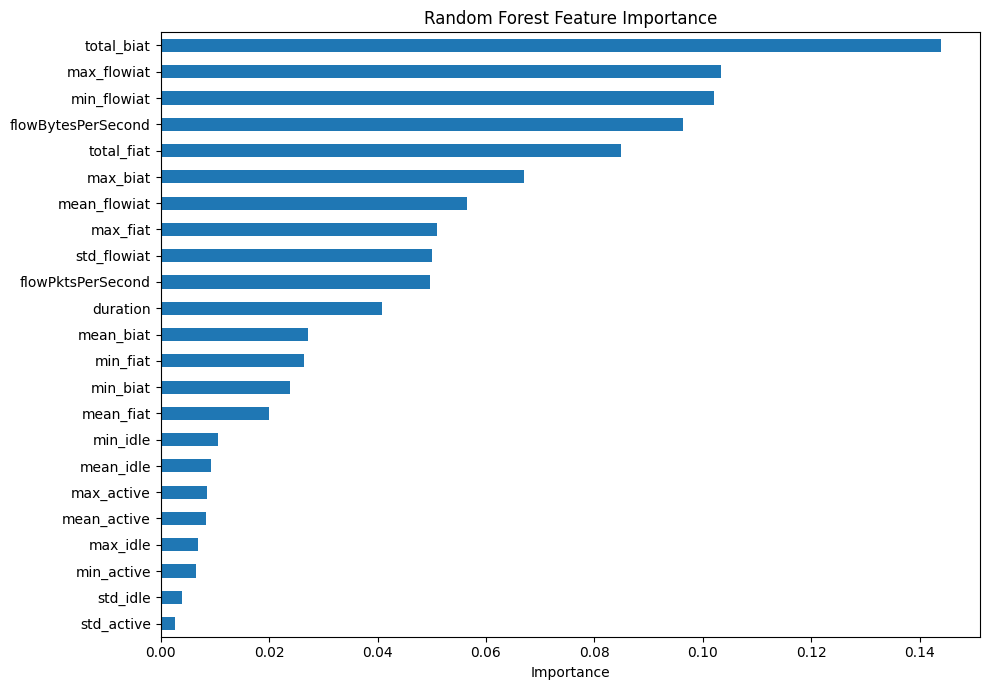

In [15]:

import pandas as pd
import matplotlib.pyplot as plt

rf_best = rf_search.best_estimator_

importances = pd.Series(
    rf_best.named_steps["model"].feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print("Feature importance ranking:")
display(importances.to_frame("Importance"))

plt.figure(figsize=(10, 7))
importances.sort_values().plot(kind="barh")
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()


In [16]:

from sklearn.base import clone
from sklearn.metrics import accuracy_score, f1_score

feature_results = []

for n in [10, 15, 20, 23]:
    selected = importances.head(n).index.tolist()

    model = clone(rf_best)

    model.fit(X_train[selected], y_train)
    predictions = model.predict(X_val[selected])

    feature_results.append({
        "Features": n,
        "Accuracy": accuracy_score(y_val, predictions),
        "F1": f1_score(y_val, predictions)
    })

feature_comparison = pd.DataFrame(feature_results)

display(feature_comparison.sort_values("F1", ascending=False))


,Features,Accuracy,F1
3,23,0.750933,0.773687
1,15,0.751146,0.770434
2,20,0.750880,0.768926
0,10,0.738405,0.757259


In [17]:

from sklearn.metrics import accuracy_score, f1_score
import numpy as np

original_pred = rf_best.predict(X_val)

print("Saved tuned Random Forest:")
print("Accuracy:", accuracy_score(y_val, original_pred))
print("F1:", f1_score(y_val, original_pred))

print("\nCurrent training shape:", X_train.shape)
print("Current validation shape:", X_val.shape)

print("\nTraining class counts:")
print(y_train.value_counts())

print("\nValidation class counts:")
print(y_val.value_counts())

print("\nFeature count:", len(X_train.columns))
print("Feature names match:",
      list(X_train.columns) == list(X_val.columns))


Saved tuned Random Forest:
Accuracy: 0.7596225610406226
F1: 0.7735650077838598

Current training shape: (18758, 23)
Current validation shape: (18758, 23)

Training class counts:
label
1    9793
0    8965
Name: count, dtype: int64

Validation class counts:
label
1    9793
0    8965
Name: count, dtype: int64

Feature count: 23
Feature names match: True


In [18]:

from sklearn.model_selection import train_test_split

app_df = test_df.copy()

app_df["app_label"] = (
    app_df["label"]
    .str.upper()
    .str.replace("VPN-", "", regex=False)
)

app_features = [
    col for col in app_df.columns
    if col not in ["label", "app_label"]
]

X_app = app_df[app_features].replace(
    [np.inf, -np.inf], np.nan
)

y_app = app_df["app_label"]

X_app_train, X_app_test, y_app_train, y_app_test = (
    train_test_split(
        X_app,
        y_app,
        test_size=0.2,
        stratify=y_app,
        random_state=42
    )
)

print("Training rows:", len(X_app_train))
print("Testing rows:", len(X_app_test))
print("\nApplication counts:")
print(y_app.value_counts())


Training rows: 15006
Testing rows: 3752

Application counts:
app_label
VOIP         5097
BROWSING     5000
FT           2950
CHAT         2086
P2P          1928
STREAMING     957
MAIL          740
Name: count, dtype: int64


In [19]:

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report
)

encoder = LabelEncoder()
y_app_train_encoded = encoder.fit_transform(y_app_train)
y_app_test_encoded = encoder.transform(y_app_test)

app_models = {
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ))
    ]),
    "XGBoost": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", XGBClassifier(
            n_estimators=200,
            max_depth=5,
            learning_rate=0.1,
            tree_method="hist",
            eval_metric="mlogloss",
            random_state=42,
            n_jobs=-1
        ))
    ])
}

app_results = []

for name, model in app_models.items():
    model.fit(X_app_train, y_app_train_encoded)
    pred = model.predict(X_app_test)

    app_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_app_test_encoded, pred),
        "Macro F1": f1_score(
            y_app_test_encoded,
            pred,
            average="macro"
        ),
        "Weighted F1": f1_score(
            y_app_test_encoded,
            pred,
            average="weighted"
        )
    })

    print("\n", name)
    print(classification_report(
        y_app_test_encoded,
        pred,
        target_names=encoder.classes_,
        zero_division=0
    ))

display(pd.DataFrame(app_results))



 Random Forest
              precision    recall  f1-score   support

    BROWSING       0.89      0.94      0.91      1000
        CHAT       0.78      0.72      0.75       417
          FT       0.84      0.78      0.81       590
        MAIL       0.84      0.91      0.87       148
         P2P       0.83      0.91      0.87       386
   STREAMING       0.89      0.81      0.85       191
        VOIP       1.00      0.99      0.99      1020

    accuracy                           0.89      3752
   macro avg       0.87      0.86      0.86      3752
weighted avg       0.89      0.89      0.89      3752


 XGBoost
              precision    recall  f1-score   support

    BROWSING       0.90      0.95      0.92      1000
        CHAT       0.85      0.74      0.79       417
          FT       0.86      0.82      0.84       590
        MAIL       0.83      0.94      0.88       148
         P2P       0.83      0.93      0.88       386
   STREAMING       0.89      0.79      0.83       19

,Model,Accuracy,Macro F1,Weighted F1
0,Random Forest,0.890725,0.863805,0.889661
1,XGBoost,0.902719,0.876085,0.901759


In [20]:

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# Prepare Scenario B
b_app_df = b_df.copy()

b_app_df["app_label"] = (
    b_app_df["label"]
    .str.upper()
    .str.replace("VPN-", "", regex=False)
)

# Use exactly the same feature order
X_b_app = b_app_df[app_features].replace(
    [np.inf, -np.inf], np.nan
)

y_b_app = encoder.transform(b_app_df["app_label"])

# Evaluate models trained on A2 training split
b_app_results = []

for name, model in app_models.items():
    predictions = model.predict(X_b_app)

    b_app_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_b_app, predictions),
        "Macro F1": f1_score(
            y_b_app, predictions, average="macro"
        ),
        "Weighted F1": f1_score(
            y_b_app, predictions, average="weighted"
        )
    })

    print("\n", name)
    print(classification_report(
        y_b_app,
        predictions,
        target_names=encoder.classes_,
        zero_division=0
    ))

display(pd.DataFrame(b_app_results))



 Random Forest
              precision    recall  f1-score   support

    BROWSING       0.73      0.81      0.77      5000
        CHAT       0.79      0.31      0.44      2086
          FT       0.45      0.80      0.57      2950
        MAIL       0.92      0.39      0.54       740
         P2P       0.78      0.82      0.80      1928
   STREAMING       0.97      0.17      0.28       957
        VOIP       0.99      0.90      0.94      5097

    accuracy                           0.73     18758
   macro avg       0.80      0.60      0.62     18758
weighted avg       0.79      0.73      0.72     18758


 XGBoost
              precision    recall  f1-score   support

    BROWSING       0.77      0.79      0.78      5000
        CHAT       0.67      0.33      0.44      2086
          FT       0.40      0.73      0.52      2950
        MAIL       0.79      0.31      0.44       740
         P2P       0.73      0.92      0.81      1928
   STREAMING       0.94      0.33      0.48       95

,Model,Accuracy,Macro F1,Weighted F1
0,Random Forest,0.728542,0.621802,0.718613
1,XGBoost,0.706099,0.624840,0.706684


In [21]:

import numpy as np
import pandas as pd

comparison_rows = []

for feature in app_features:
    a = pd.to_numeric(
        test_df[feature], errors="coerce"
    ).replace([np.inf, -np.inf], np.nan).dropna()

    b = pd.to_numeric(
        b_df[feature], errors="coerce"
    ).replace([np.inf, -np.inf], np.nan).dropna()

    a_median = a.median()
    b_median = b.median()

    # Symmetric relative difference between medians
    difference = (
        abs(a_median - b_median)
        / max(abs(a_median), abs(b_median), 1e-9)
    )

    comparison_rows.append({
        "Feature": feature,
        "A2 Median": a_median,
        "B Median": b_median,
        "Relative Difference": difference
    })

distribution_df = pd.DataFrame(comparison_rows)

display(
    distribution_df.sort_values(
        "Relative Difference", ascending=False
    ).head(15)
)


,Feature,A2 Median,B Median,Relative Difference
2,total_biat,1.016825e+07,2.100000e+01,0.999998
1,total_fiat,1.028026e+07,6.200000e+01,0.999994
4,min_biat,2.100000e+01,2.865800e+05,0.999927
3,min_fiat,6.200000e+01,2.821430e+05,0.999780
6,max_biat,2.865800e+05,3.526250e+04,0.876954
5,max_fiat,2.821430e+05,5.104959e+04,0.819065
7,mean_fiat,5.104959e+04,1.164916e+04,0.771807
8,mean_biat,3.526250e+04,9.605910e+03,0.727589
0,duration,1.109263e+07,1.109263e+07,0.000000
9,flowPktsPerSecond,1.168122e+01,1.168122e+01,0.000000


In [22]:

a2_ordered = pd.concat(
    [test_nonvpn, test_vpn],
    ignore_index=True
)

b_ordered = b_df.reset_index(drop=True)

print("Same number of rows:",
      len(a2_ordered) == len(b_ordered))

print("Same labels in the same row positions:",
      (a2_ordered["label"].to_numpy() ==
       b_ordered["label"].to_numpy()).mean())

print("\nFirst 10 labels in A2:")
print(a2_ordered["label"].head(10).tolist())

print("\nFirst 10 labels in B:")
print(b_ordered["label"].head(10).tolist())


Same number of rows: True
Same labels in the same row positions: 0.0

First 10 labels in A2:
['BROWSING', 'BROWSING', 'BROWSING', 'BROWSING', 'BROWSING', 'BROWSING', 'BROWSING', 'BROWSING', 'BROWSING', 'BROWSING']

First 10 labels in B:
['CHAT', 'CHAT', 'CHAT', 'CHAT', 'CHAT', 'CHAT', 'CHAT', 'CHAT', 'CHAT', 'CHAT']


In [23]:

from pathlib import Path
import re

def raw_attribute_order(path):
    attributes = []

    with open(path, "r", encoding="utf-8", errors="replace") as f:
        for line in f:
            line = line.strip()

            if line.lower().startswith("@attribute"):
                match = re.match(
                    r"""@attribute\s+['"]?([^'"\s]+)""",
                    line,
                    flags=re.IGNORECASE
                )

                if match:
                    attributes.append(match.group(1))

            elif line.lower().startswith("@data"):
                break

    return attributes

a2_path = next(
    p for p in Path("/content/datasets").rglob("*.arff")
    if "Scenario A2-ARFF" in str(p)
    and p.name == "TimeBasedFeatures-Dataset-15s-NO-VPN.arff"
)

b_path = next(
    p for p in Path("/content/datasets").rglob("*.arff")
    if "Scenario B-ARFF" in str(p)
    and p.name == "TimeBasedFeatures-Dataset-15s.arff"
)

a2_attrs = raw_attribute_order(a2_path)
b_attrs = raw_attribute_order(b_path)

print("A2 raw feature order:")
print(a2_attrs)

print("\nB raw feature order:")
print(b_attrs)

print("\nSide-by-side comparison:")
for i, (a, b) in enumerate(zip(a2_attrs, b_attrs)):
    marker = "MATCH" if a == b else "DIFFERENT"
    print(f"{i:2d}: {a:25s} | {b:25s} | {marker}")


A2 raw feature order:
['duration', 'total_fiat', 'total_biat', 'min_fiat', 'min_biat', 'max_fiat', 'max_biat', 'mean_fiat', 'mean_biat', 'flowPktsPerSecond', 'flowBytesPerSecond', 'min_flowiat', 'max_flowiat', 'mean_flowiat', 'std_flowiat', 'min_active', 'mean_active', 'max_active', 'std_active', 'min_idle', 'mean_idle', 'max_idle', 'std_idle', 'class1']

B raw feature order:
['duration', 'total_fiat', 'total_biat', 'min_fiat', 'min_biat', 'max_fiat', 'max_biat', 'mean_fiat', 'mean_biat', 'flowPktsPerSecond', 'flowBytesPerSecond', 'min_flowiat', 'max_flowiat', 'mean_flowiat', 'std_flowiat', 'min_active', 'mean_active', 'max_active', 'std_active', 'min_idle', 'mean_idle', 'max_idle', 'std_idle', 'class1']

Side-by-side comparison:
 0: duration                  | duration                  | MATCH
 1: total_fiat                | total_fiat                | MATCH
 2: total_biat                | total_biat                | MATCH
 3: min_fiat                  | min_fiat                  | MA

In [24]:

import pandas as pd

# Features whose medians appeared identical
stable_features = [
    "duration",
    "flowPktsPerSecond",
    "flowBytesPerSecond",
    "min_flowiat",
    "max_flowiat",
    "mean_flowiat",
    "std_flowiat"
]

a2_stable = test_df[stable_features].copy()
b_stable = b_df[stable_features].copy()

a2_hashes = pd.util.hash_pandas_object(
    a2_stable, index=False
)

b_hashes = pd.util.hash_pandas_object(
    b_stable, index=False
)

shared = len(set(a2_hashes) & set(b_hashes))

print("A2 unique stable-feature records:", a2_hashes.nunique())
print("B unique stable-feature records:", b_hashes.nunique())
print("Shared stable-feature records:", shared)
print(
    "Overlap relative to A2 unique records:",
    shared / max(a2_hashes.nunique(), 1)
)


A2 unique stable-feature records: 18006
B unique stable-feature records: 18006
Shared stable-feature records: 18006
Overlap relative to A2 unique records: 1.0


In [25]:

import pandas as pd
import numpy as np

stable_features = [
    "duration",
    "flowPktsPerSecond",
    "flowBytesPerSecond",
    "min_flowiat",
    "max_flowiat",
    "mean_flowiat",
    "std_flowiat"
]

a2_check = test_df.reset_index(drop=True).copy()
b_check = b_df.reset_index(drop=True).copy()

a2_check["_key"] = pd.util.hash_pandas_object(
    a2_check[stable_features], index=False
)

b_check["_key"] = pd.util.hash_pandas_object(
    b_check[stable_features], index=False
)

# Only use unique keys to avoid ambiguous matches
a2_unique = a2_check[
    ~a2_check["_key"].duplicated(keep=False)
]

b_unique = b_check[
    ~b_check["_key"].duplicated(keep=False)
]

matched = a2_unique.merge(
    b_unique,
    on="_key",
    suffixes=("_A2", "_B"),
    validate="one_to_one"
)

print("Unambiguous matched records:", len(matched))

print("Same application labels:",
      (
          matched["label_A2"] ==
          matched["label_B"]
      ).mean())

print("\nFirst 8 feature values for a matched record:")

first_eight = [
    "total_fiat", "total_biat",
    "min_fiat", "min_biat",
    "max_fiat", "max_biat",
    "mean_fiat", "mean_biat"
]

display(pd.DataFrame({
    "Feature": first_eight,
    "A2 value": [
        matched.iloc[0][f"{f}_A2"]
        for f in first_eight
    ],
    "B value": [
        matched.iloc[0][f"{f}_B"]
        for f in first_eight
    ]
}))


Unambiguous matched records: 17878
Same application labels: 1.0

First 8 feature values for a matched record:


,Feature,A2 value,B value
0,total_fiat,1.499346e+07,0.000000
1,total_biat,1.496781e+07,0.000000
2,min_fiat,0.000000e+00,823486.000000
3,min_biat,0.000000e+00,854818.000000
4,max_fiat,8.234860e+05,873.134288
5,max_biat,8.548180e+05,287.914517
6,mean_fiat,8.731343e+02,14376.965266
7,mean_biat,2.879145e+02,8388.288217


In [26]:

first_eight = [
    "total_fiat", "total_biat",
    "min_fiat", "min_biat",
    "max_fiat", "max_biat",
    "mean_fiat", "mean_biat"
]

mapping_results = []

for a_feature in first_eight:
    for b_feature in first_eight:
        a_values = matched[f"{a_feature}_A2"].to_numpy()
        b_values = matched[f"{b_feature}_B"].to_numpy()

        match_rate = np.isclose(
            a_values,
            b_values,
            rtol=1e-9,
            atol=1e-9,
            equal_nan=True
        ).mean()

        mapping_results.append({
            "A2 Feature": a_feature,
            "B Feature": b_feature,
            "Exact Match Rate": match_rate
        })

mapping_df = pd.DataFrame(mapping_results)

display(
    mapping_df.sort_values(
        "Exact Match Rate", ascending=False
    ).head(20)
)


,A2 Feature,B Feature,Exact Match Rate
25,min_biat,total_biat,1.000000
16,min_fiat,total_fiat,1.000000
43,max_biat,min_biat,1.000000
34,max_fiat,min_fiat,1.000000
52,mean_fiat,max_fiat,1.000000
61,mean_biat,max_biat,1.000000
27,min_biat,min_biat,0.232409
41,max_biat,total_biat,0.232409
32,max_fiat,total_fiat,0.210426
18,min_fiat,min_fiat,0.210426


In [27]:

import numpy as np
import pandas as pd

all_features = [
    c for c in test_df.columns
    if c != "label"
]

mapping_rows = []

for a_feature in all_features:
    a_values = matched[f"{a_feature}_A2"].to_numpy(
        dtype=float
    )

    for b_feature in all_features:
        b_values = matched[f"{b_feature}_B"].to_numpy(
            dtype=float
        )

        rate = np.isclose(
            a_values,
            b_values,
            rtol=1e-9,
            atol=1e-9,
            equal_nan=True
        ).mean()

        mapping_rows.append({
            "A2 Feature": a_feature,
            "B Feature": b_feature,
            "Match Rate": rate
        })

full_mapping = pd.DataFrame(mapping_rows)

best_mapping = (
    full_mapping
    .sort_values("Match Rate", ascending=False)
    .drop_duplicates("A2 Feature")
    .sort_values("A2 Feature")
)

display(best_mapping)


,A2 Feature,B Feature,Match Rate
0,duration,duration,1.000000
240,flowBytesPerSecond,flowBytesPerSecond,1.000000
216,flowPktsPerSecond,flowPktsPerSecond,1.000000
408,max_active,max_active,1.000000
142,max_biat,min_biat,1.000000
118,max_fiat,min_fiat,1.000000
288,max_flowiat,max_flowiat,1.000000
504,max_idle,max_idle,1.000000
384,mean_active,mean_active,1.000000
190,mean_biat,max_biat,1.000000


In [28]:

label_match_rate = (
    matched["label_A2"].to_numpy() ==
    matched["label_B"].to_numpy()
).mean()

print("Matched records:", len(matched))
print("Matching application labels:", label_match_rate)

print("\nLabel mismatches:")
display(
    matched.loc[
        matched["label_A2"] != matched["label_B"],
        ["label_A2", "label_B"]
    ].head(10)
)


Matched records: 17878
Matching application labels: 1.0

Label mismatches:


,label_A2,label_B


In [29]:

import numpy as np
import pandas as pd

# A2 feature name -> corresponding B column
feature_mapping = {
    "duration": "duration",
    "min_fiat": "total_fiat",
    "min_biat": "total_biat",
    "max_fiat": "min_fiat",
    "max_biat": "min_biat",
    "mean_fiat": "max_fiat",
    "mean_biat": "max_biat",
    "flowPktsPerSecond": "flowPktsPerSecond",
    "flowBytesPerSecond": "flowBytesPerSecond",
    "min_flowiat": "min_flowiat",
    "max_flowiat": "max_flowiat",
    "mean_flowiat": "mean_flowiat",
    "std_flowiat": "std_flowiat",
    "min_active": "min_active",
    "mean_active": "mean_active",
    "max_active": "max_active",
    "std_active": "std_active",
    "min_idle": "min_idle",
    "mean_idle": "mean_idle",
    "max_idle": "max_idle",
    "std_idle": "std_idle"
}

# Create an aligned copy, without modifying b_df
b_aligned = pd.DataFrame({
    a2_name: b_df[b_name].to_numpy()
    for a2_name, b_name in feature_mapping.items()
})

b_aligned["label"] = b_df["label"].to_numpy()

print("Aligned features:", len(feature_mapping))
print("Rows:", len(b_aligned))
print("Excluded:", ["total_fiat", "total_biat"])


Aligned features: 21
Rows: 18758
Excluded: ['total_fiat', 'total_biat']


In [30]:

aligned_features = list(feature_mapping.keys())

a2_records = test_df[aligned_features + ["label"]].copy()
b_records = b_aligned[aligned_features + ["label"]].copy()

a2_hashes = pd.util.hash_pandas_object(
    a2_records, index=False
)

b_hashes = pd.util.hash_pandas_object(
    b_records, index=False
)

print("A2 unique aligned records:", a2_hashes.nunique())
print("B unique aligned records:", b_hashes.nunique())

print("Shared unique aligned records:",
      len(set(a2_hashes) & set(b_hashes)))

print("Same full multiset of records:",
      a2_hashes.value_counts().sort_index().equals(
          b_hashes.value_counts().sort_index()
      ))


A2 unique aligned records: 18074
B unique aligned records: 18074
Shared unique aligned records: 18074
Same full multiset of records: True


In [31]:

from pathlib import Path

root = Path("/content/datasets")

print("DATASET FILE INVENTORY\n")

for scenario in sorted(root.iterdir()):
    if scenario.is_dir():
        print(f"\n{scenario.name}")

        for path in sorted(scenario.rglob("*")):
            if path.is_file():
                print(
                    "  ",
                    path.relative_to(scenario),
                    f"({path.stat().st_size / 1024:.1f} KB)"
                )

print("\n\nPOTENTIAL SESSION / CAPTURE IDENTIFIERS\n")

keywords = [
    "session", "capture", "flowid",
    "timestamp", "pcap", "source",
    "destination", "trace"
]

for name, df in datasets.items():
    matches = [
        column for column in df.columns
        if any(word in column.lower() for word in keywords)
    ]

    if matches:
        print(name, ":", matches)

print("\nDone.")


DATASET FILE INVENTORY


Scenario A1-ARFF
   TimeBasedFeatures-Dataset-120s-VPN.arff (1823.0 KB)
   TimeBasedFeatures-Dataset-15s-VPN.arff (3504.3 KB)
   TimeBasedFeatures-Dataset-30s-VPN.arff (2780.9 KB)
   TimeBasedFeatures-Dataset-60s-VPN.arff (2892.6 KB)

Scenario A2-ARFF
   TimeBasedFeatures-Dataset-120s-NO-VPN.arff (941.6 KB)
   TimeBasedFeatures-Dataset-120s-VPN.arff (955.1 KB)
   TimeBasedFeatures-Dataset-15s-NO-VPN.arff (1561.1 KB)
   TimeBasedFeatures-Dataset-15s-VPN.arff (1784.6 KB)
   TimeBasedFeatures-Dataset-30s-NO-VPN.arff (1228.4 KB)
   TimeBasedFeatures-Dataset-30s-VPN.arff (1433.5 KB)
   TimeBasedFeatures-Dataset-60s-NO-VPN.arff (1559.5 KB)
   TimeBasedFeatures-Dataset-60s-VPN.arff (1232.9 KB)

Scenario B-ARFF
   TimeBasedFeatures-Dataset-120s-AllinOne.arff (1946.1 KB)
   TimeBasedFeatures-Dataset-120s.arff (1968.1 KB)
   TimeBasedFeatures-Dataset-15s-AllinOne.arff (3504.2 KB)
   TimeBasedFeatures-Dataset-15s.arff (3542.5 KB)
   TimeBasedFeatures-Dataset-30s-AllinOne.

In [32]:

import numpy as np
from sklearn.utils.class_weight import compute_sample_weight

sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_app_train_encoded
)

print("Sample weights calculated.")
print("Minimum weight:", sample_weights.min())
print("Maximum weight:", sample_weights.max())


Sample weights calculated.
Minimum weight: 0.525806790707453
Maximum weight: 3.621138996138996


In [33]:

from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

weighted_xgb = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", XGBClassifier(
        n_estimators=200,
        max_depth=5,
        learning_rate=0.1,
        tree_method="hist",
        eval_metric="mlogloss",
        random_state=42,
        n_jobs=-1
    ))
])

weighted_xgb.fit(
    X_app_train,
    y_app_train_encoded,
    model__sample_weight=sample_weights
)

print("Weighted XGBoost training complete.")


Weighted XGBoost training complete.


In [34]:

import pandas as pd
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report
)

models_to_compare = {
    "Original XGBoost": app_models["XGBoost"],
    "Weighted XGBoost": weighted_xgb
}

results = []

for name, model in models_to_compare.items():
    predictions = model.predict(X_app_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(
            y_app_test_encoded, predictions
        ),
        "Macro F1": f1_score(
            y_app_test_encoded,
            predictions,
            average="macro"
        ),
        "Weighted F1": f1_score(
            y_app_test_encoded,
            predictions,
            average="weighted"
        )
    })

    print("\n", name)
    print(classification_report(
        y_app_test_encoded,
        predictions,
        target_names=encoder.classes_,
        zero_division=0
    ))

display(pd.DataFrame(results))



 Original XGBoost
              precision    recall  f1-score   support

    BROWSING       0.90      0.95      0.92      1000
        CHAT       0.85      0.74      0.79       417
          FT       0.86      0.82      0.84       590
        MAIL       0.83      0.94      0.88       148
         P2P       0.83      0.93      0.88       386
   STREAMING       0.89      0.79      0.83       191
        VOIP       1.00      0.98      0.99      1020

    accuracy                           0.90      3752
   macro avg       0.88      0.88      0.88      3752
weighted avg       0.90      0.90      0.90      3752


 Weighted XGBoost
              precision    recall  f1-score   support

    BROWSING       0.91      0.90      0.91      1000
        CHAT       0.74      0.77      0.75       417
          FT       0.88      0.76      0.81       590
        MAIL       0.74      0.97      0.84       148
         P2P       0.82      0.94      0.88       386
   STREAMING       0.82      0.83      0

,Model,Accuracy,Macro F1,Weighted F1
0,Original XGBoost,0.902719,0.876085,0.901759
1,Weighted XGBoost,0.886994,0.857692,0.887077


In [35]:

import joblib
from pathlib import Path

output_dir = Path("/content/experience_budget_models")
output_dir.mkdir(parents=True, exist_ok=True)

# Model 1: VPN / Non-VPN
vpn_features = list(X_train.columns)

vpn_bundle = {
    "model": rf_search.best_estimator_,
    "features": vpn_features,
    "labels": {0: "NON-VPN", 1: "VPN"},
    "task": "binary_vpn_detection",
    "window": "15s",
    "validation": "A1-to-A2; not independent-session validated"
}

vpn_path = output_dir / "vpn_classifier_random_forest.joblib"
joblib.dump(vpn_bundle, vpn_path)

# Model 2: Seven application categories
application_features = list(X_app_train.columns)

application_bundle = {
    "model": app_models["XGBoost"],
    "features": application_features,
    "label_encoder": encoder,
    "task": "seven_class_application_classification",
    "window": "15s",
    "validation": "random 80/20 A2 split; not independent-session validated"
}

app_path = output_dir / "application_classifier_xgboost.joblib"
joblib.dump(application_bundle, app_path)

print("Both models saved successfully!\n")

for path in [vpn_path, app_path]:
    print(
        path.name,
        "-",
        round(path.stat().st_size / (1024 * 1024), 2),
        "MB"
    )


Both models saved successfully!

vpn_classifier_random_forest.joblib - 16.67 MB
application_classifier_xgboost.joblib - 2.8 MB


In [36]:

from google.colab import files

files.download(str(vpn_path))
files.download(str(app_path))


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>